# Фаза 2 • Неделя 8 • Четверг
## Нейронные сети
### 🔥 PyTorch: fine tuning

### Подготовка к работе

1. Загрузи этот ноутбук на Google Colab
2. Подгрузи архив [датасета](https://www.kaggle.com/datasets/ikobzev/architectural-heritage-elements-image64-dataset) в свое пространство и разархивируй его с помощью `unzip`. 

In [133]:
import torch
import torch.nn as nn
import torchutils as tu
from torch.utils.data import DataLoader
from torchvision import datasets, transforms as T
from torchvision.models import (
    convnext_tiny, ConvNeXt_Tiny_Weights,
    resnet18, ResNet18_Weights,
    mobilenet_v3_small, MobileNet_V3_Small_Weights,
)
from PIL import Image
from urllib.request import urlretrieve
import zipfile
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)

import os
from torchvision import transforms
import torchvision
from torchvision import transforms

from torchvision.models import resnet18, ResNet18_Weights

import pandas as pd

Устройство: cpu


In [4]:
with zipfile.ZipFile("archive.zip") as archive:
    archive.extractall("archive_task")

1. Убедись, что структура папок соответствует задаче классификации (либо приведите ее к формату, указанному ниже): 

        `train`
        
            - class_1
            - class_2
            - ...
            - class_n
            
        `valid`

            - class_1
            - class_2
            - ...
            - class_n

In [8]:
print(os.listdir("archive_task"))

['test', 'train']


In [9]:
print('Train:', os.listdir('archive_task/train'))
print('Test:', os.listdir('archive_task/test'))

Train: ['altar', 'apse', 'bell_tower', 'column', 'dome(inner)', 'dome(outer)', 'flying_buttress', 'gargoyle', 'stained_glass', 'vault']
Test: ['altar', 'apse', 'bell_tower', 'column', 'dome(inner)', 'dome(outer)', 'flying_buttress', 'gargoyle', 'stained_glass', 'vault']


In [10]:
os.rename('archive_task/test', 'archive_task/valid')

In [11]:
print(os.listdir('archive_task'))

['train', 'valid']


2. Создай `DataLoader` в для обучающей и валидационных выборок. Примените аугментации к изображениям. 

In [140]:
train_transform = T.Compose([
    T.Resize((64, 64)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

valid_transform = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

In [141]:
train_dataset = torchvision.datasets.ImageFolder("archive_task/train", transform=train_transform)
valid_dataset = torchvision.datasets.ImageFolder("archive_task/valid", transform=valid_transform)

In [142]:
print(len(train_dataset))
print(len(valid_dataset))
print(train_dataset.classes)

10130
1404
['altar', 'apse', 'bell_tower', 'column', 'dome(inner)', 'dome(outer)', 'flying_buttress', 'gargoyle', 'stained_glass', 'vault']


In [143]:
# проверяем размер батча
image, label = train_dataset[0]
print(image.size())

torch.Size([3, 64, 64])


In [144]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

In [145]:
images, labels = next(iter(train_loader))

print("Изображения:", images.shape)
print("Метки:", labels.shape)

Изображения: torch.Size([32, 3, 64, 64])
Метки: torch.Size([32])


3. Создай экземпляр предобученной модели: [torchvision models](https://pytorch.org/vision/stable/models.html). Можно взять любую модель для baseline, а дальше попробовать что-то более сложное. 

In [146]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(DEVICE).eval()

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [147]:
print(train_dataset.classes)

['altar', 'apse', 'bell_tower', 'column', 'dome(inner)', 'dome(outer)', 'flying_buttress', 'gargoyle', 'stained_glass', 'vault']


5. Замени выходной слой форматом, который подходит под задачу: бинарная или многоклассовая классификация. 

In [98]:
num_classes = len(train_dataset.classes)
print(num_classes)

10


In [148]:
model.fc = torch.nn.Linear(in_features=512, out_features=num_classes)

# bias=True - у слоя есть дополнительный обучаемый параметр - bias

In [100]:
print(model.fc)

Linear(in_features=512, out_features=10, bias=True)


6. Обучи модель (только последний слой!) и зафиксируй метрику на валидационной части выборки. 

Замораживаем все слои, кроме последнего

In [149]:
for param in model.parameters():
    param.requires_grad = False # requires_grad = False — запрещаем обновлять веса

for param in model.fc.parameters():
    param.requires_grad = True

In [150]:
print("Обучаемые параметры:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Обучаемые параметры:
fc.weight
fc.bias


Подготавливаем обучение

In [151]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [154]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

Обучаем модель

In [155]:
train_losses, valid_losses = [], []
train_accs, valid_accs = [], []

for epoch in range(3):
    # Свёрточная часть остаётся в режиме eval
    model.eval()
    train_loss = train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)
        predicted = logits.argmax(dim=1)
        train_correct += (predicted == labels).sum().item()

    valid_loss = valid_correct = 0

    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            valid_loss += criterion(logits, labels).item() * len(labels)

            predicted = logits.argmax(dim=1)
            valid_correct += (predicted == labels).sum().item()

    train_losses.append(train_loss / len(train_dataset))
    valid_losses.append(valid_loss / len(valid_dataset))
    train_accs.append(train_correct / len(train_dataset))
    valid_accs.append(valid_correct / len(valid_dataset))

    print(f"Эпоха {epoch + 1}: "
          f"train loss={train_losses[-1]:.3f}, val loss={valid_losses[-1]:.3f}, "
          f"train acc={train_accs[-1]:.1%}, val acc={valid_accs[-1]:.1%}")

Эпоха 1: train loss=0.555, val loss=0.622, train acc=81.3%, val acc=79.1%
Эпоха 2: train loss=0.471, val loss=0.432, train acc=84.1%, val acc=85.2%
Эпоха 3: train loss=0.434, val loss=0.464, train acc=84.8%, val acc=84.7%


In [157]:
results_df = pd.DataFrame({
    'epoch': range(1, len(train_losses) + 1),
    'train_loss': train_losses,
    'valid_loss': valid_losses,
    'train_accuracy': train_accs,
    'valid_accuracy': valid_accs
})

results_df['stage'] = 'До разморозки'

results_df

,epoch,train_loss,valid_loss,train_accuracy,valid_accuracy,stage
0,1,0.555061,0.621916,0.813031,0.791311,До разморозки
1,2,0.471100,0.432379,0.841066,0.851852,До разморозки
2,3,0.433671,0.464293,0.848371,0.846866,До разморозки


7. Распечатай изображение из тестовой выборки и подпиши класс картинки, предсказанный моделью. 

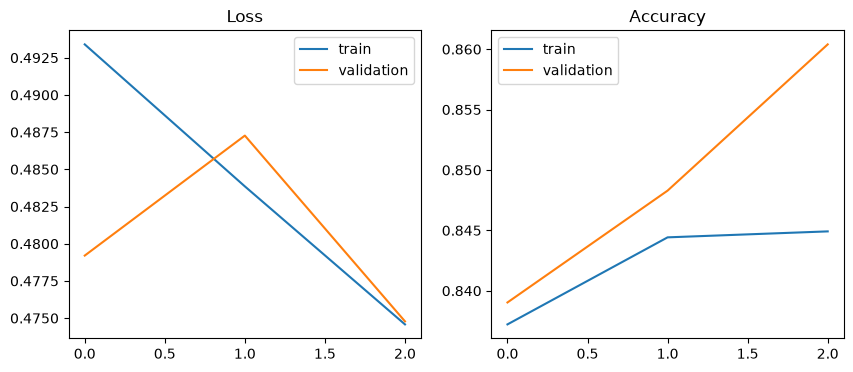

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(train_losses, label="train")
axes[0].plot(valid_losses, label="validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(train_accs, label="train")
axes[1].plot(valid_accs, label="validation")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.show()

Предсказанный класс: column
Правильный класс: column


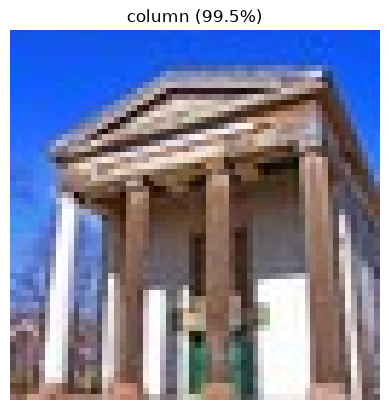

In [159]:
image, label = valid_dataset[448]

x = image.unsqueeze(0).to(device)

model.eval()
with torch.inference_mode():
    probabilities = torch.softmax(model(x), dim=1)
    predicted = probabilities.argmax(dim=1).item()

predicted_class = valid_dataset.classes[predicted]
confidence = probabilities[0, predicted].item()

image_to_show = image.permute(1, 2, 0).numpy().copy()

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

for channel in range(3):
    image_to_show[:, :, channel] = (
        image_to_show[:, :, channel] * std[channel] + mean[channel]
    )

plt.imshow(image_to_show.clip(0, 1))
plt.title(f"{predicted_class} ({confidence:.1%})")
plt.axis("off")
plt.show()

8. "Разморозь" несоклько слоев базовой модели и вновь обучи ее. Зафиксируй метрику качества для модели. О том, как сделать unfreeze нескольких слоев сразу, а не только последнего, можно почитать тут: [discuss.pytorch.org](https://discuss.pytorch.org/t/how-the-pytorch-freeze-network-in-some-layers-only-the-rest-of-the-training/7088/3)

In [160]:
for name, layer in model.named_children():
    print(name)

conv1
bn1
relu
maxpool
layer1
layer2
layer3
layer4
avgpool
fc


In [161]:
for name, layer in model.named_children():
    print(name, sum(p.numel() for p in layer.parameters()))

conv1 9408
bn1 128
relu 0
maxpool 0
layer1 147968
layer2 525568
layer3 2099712
layer4 8393728
avgpool 0
fc 5130


In [162]:
for param in model.layer4.parameters():
    param.requires_grad = True

print("Обучаемые параметры:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Обучаемые параметры:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


нужно пересоздать оптимизатор, чтобы он учитывал параметры обоих блоков

In [163]:
optimizer = torch.optim.Adam(
    [
        {'params': model.layer4.parameters()},
        {'params': model.fc.parameters()}
    ],
    lr=0.002
)

обучаем модель с размороженными слоями

In [166]:
train_losses_ft, valid_losses_ft = [], [] # Создадим отдельные списки для новых метрик
train_accs_ft, valid_accs_ft = [], []

for epoch in range(3):
    model.eval()
    train_loss = train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)
        predicted = logits.argmax(dim=1)
        train_correct += (predicted == labels).sum().item()

    valid_loss = valid_correct = 0

    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            valid_loss += criterion(logits, labels).item() * len(labels)

            predicted = logits.argmax(dim=1)
            valid_correct += (predicted == labels).sum().item()

    train_losses_ft.append(train_loss / len(train_dataset))
    valid_losses_ft.append(valid_loss / len(valid_dataset))
    train_accs_ft.append(train_correct / len(train_dataset))
    valid_accs_ft.append(valid_correct / len(valid_dataset))

    print(f"Эпоха {epoch + 1}: "
          f"train loss={train_losses_ft[-1]:.3f}, val loss={valid_losses_ft[-1]:.3f}, "
          f"train acc={train_accs_ft[-1]:.1%}, val acc={valid_accs_ft[-1]:.1%}")

Эпоха 1: train loss=2.207, val loss=2.222, train acc=18.9%, val acc=15.0%
Эпоха 2: train loss=2.207, val loss=2.223, train acc=18.9%, val acc=15.0%
Эпоха 3: train loss=2.207, val loss=2.223, train acc=18.9%, val acc=15.0%


In [167]:
new_results = pd.DataFrame({
    'epoch': range(1, len(train_losses_ft) + 1),
    'train_loss': train_losses_ft,
    'valid_loss': valid_losses_ft,
    'train_accuracy': train_accs_ft,
    'valid_accuracy': valid_accs_ft,
    'stage': 'После разморозки'
})

results_df = pd.concat(
    [results_df, new_results],
    ignore_index=True
)

results_df

,epoch,train_loss,valid_loss,train_accuracy,valid_accuracy,stage
0,1,0.555061,0.621916,0.813031,0.791311,До разморозки
1,2,0.471100,0.432379,0.841066,0.851852,До разморозки
2,3,0.433671,0.464293,0.848371,0.846866,До разморозки
3,1,2.206794,2.222451,0.188944,0.149573,После разморозки
4,2,2.206627,2.223426,0.188944,0.149573,После разморозки
5,3,2.206640,2.222714,0.188944,0.149573,После разморозки


In [170]:
print(model.layer4)

Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (downsample): Sequential(
      (0): Conv2d(256, 512, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (1): BasicBlock(
    (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), b

In [171]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

9. Сравни качество двух моделей: предобученной с замененным выходным слоем и дообученной с несколькими размороженными слоями. 

Выведем лучшие результаты каждого этапа

In [172]:
comparison_df = results_df.loc[
    results_df.groupby('stage')['valid_accuracy'].idxmax(),
    ['stage', 'epoch', 'valid_accuracy', 'valid_loss']
].reset_index(drop=True)

comparison_df

,stage,epoch,valid_accuracy,valid_loss
0,До разморозки,2,0.851852,0.432379
1,После разморозки,1,0.149573,2.222451


Посчитаем разницу в точности

In [169]:
accuracy_before = results_df[
    results_df['stage'] == 'До разморозки'
]['valid_accuracy'].max()

accuracy_after = results_df[
    results_df['stage'] == 'После разморозки'
]['valid_accuracy'].max()

difference = (accuracy_after - accuracy_before) * 100

print(f'Точность до разморозки: {accuracy_before:.2%}')
print(f'Точность после разморозки: {accuracy_after:.2%}')
print(f'Разница: {difference:+.2f} процентных пункта')

Точность до разморозки: 85.19%
Точность после разморозки: 14.96%
Разница: -70.23 процентных пункта


- Если разница положительная — после разморозки точность улучшилась.
- Если отрицательная — качество на валидации снизилось.
- Если близка к нулю — существенного изменения точности не произошло.  
Также смотрим на valid_loss: чем он меньше, тем лучше.

<img src="https://icons.iconarchive.com/icons/icons8/windows-8/256/Programming-Github-icon.png" width=32 /> Сохрани файл для __github__ и распечатай результат команды `!git status` в ячейке ниже. 

In [ ]:
# code

10. Сохрани модель (пример можно посмотреть [тут](../../learning/aux/model_saving.ipynb) или в [документации](https://pytorch.org/tutorials/beginner/saving_loading_models.html))

сохраняем модель

In [173]:
torch.save(
    model.state_dict(),
    'resnet18_finetuned.pth'
)

Проверяем, что файл появился

In [174]:
print(os.path.exists('resnet18_finetuned.pth'))

True


11. Реализуй функцию, которая на вход принимает путь к файлу, а в ответ возвращает класс объекта. 

In [175]:
import torch
from PIL import Image
from torchvision.models import resnet18

# Загружаем сохранённую модель
model_for_prediction = resnet18(weights=None)
model_for_prediction.fc = torch.nn.Linear(
    in_features=512,
    out_features=len(train_dataset.classes)
)

model_for_prediction.load_state_dict(
    torch.load('resnet18_finetuned.pth', map_location=device)
)

model_for_prediction = model_for_prediction.to(device)
model_for_prediction.eval()

# Названия классов
class_names = train_dataset.classes


# Функция предсказания
def get_prediction(image_path):
    image = Image.open(image_path).convert('RGB')

    image = valid_transform(image)
    image = image.unsqueeze(0).to(device)

    with torch.inference_mode():
        outputs = model_for_prediction(image)
        predicted = outputs.argmax(dim=1).item()

    return class_names[predicted]


# Проверяем функцию
get_prediction('photo_Joiya.jpg')

'column'

12. Сохрани ноутбук на github